# Herseninfarct Voorspellend model voor MedPredict

## 1 Inleiding

**MedPredict** is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen ondersteunt bij het vroegtijdig herkennen van gezondheidsrisic. . Het bedrijf beschikt over geanonimiseerde patiëntgegevens, waaronder demografische kenmerken, leefstijlfactoren en medische informatie

## 2 Probleemstelling

MedPredict wil onderzoeken of deze geanonimiseerde patiëntgegevens gebruikt kunnen worden om patiënten met een
verhoogd risico op een herseninfarct (stroke) vroegtijdig te identificeren. Een goed voorspellend
model kan zorgprofessionals ondersteunen bij preventie en het gericht opvolgen van patiënten met
een verhoogd risico.

## 3 De dataset

Onze dataset, die ons door FloraSense Analytics ter beschikking is gesteld, bestaat uit:
* 33550 rijen
* 22 kolommen

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
import numpy as np
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict
)

In [7]:
df_train = pd.read_csv('train.csv')
df_test_features = pd.read_csv('test.csv')
df_test_targets = pd.read_csv('sample_submission.csv')['stroke']
df_test = pd.read_csv('test.csv')

In [8]:
display(df_train.info())
display(df_train.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          

None

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


## 4. Exploratieve data-analyse (EDA)

We onderzoeken:
- Verdelingen van features
- Correlaties
- (Visuele) scheidbaarheid per soort

We gebruiken eenvoudige plots om te begrijpen welke metingen het meest onderscheidend zijn.


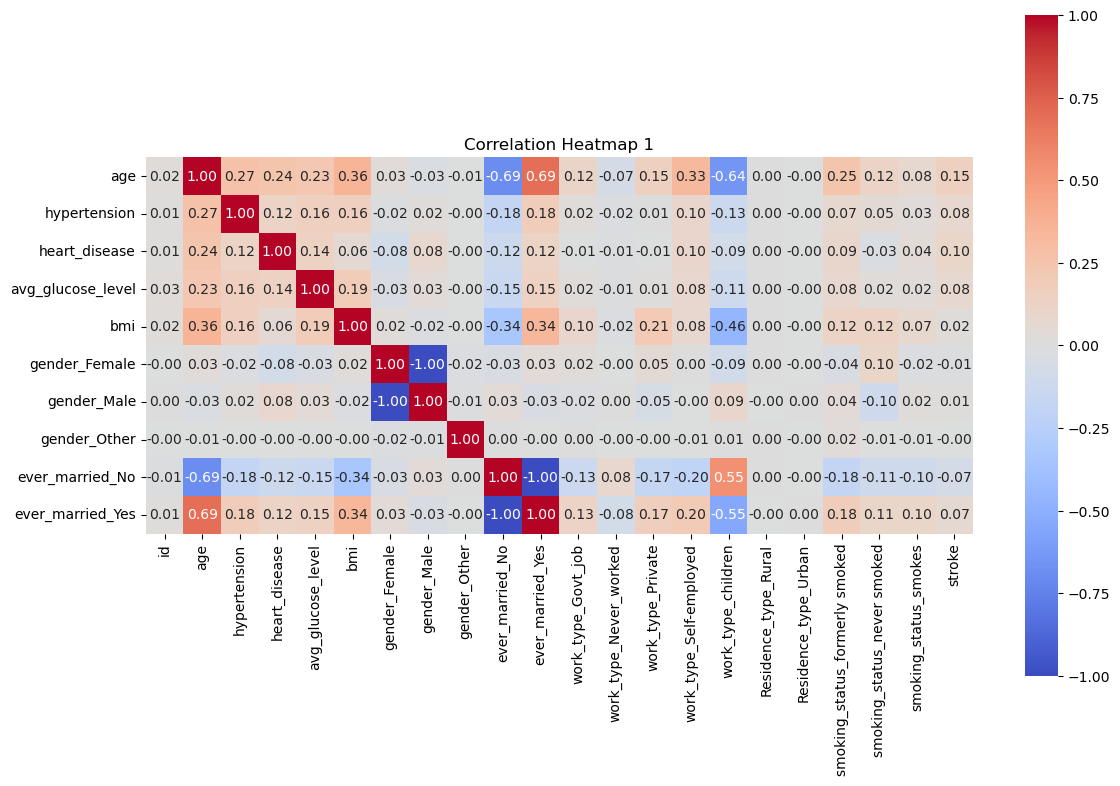

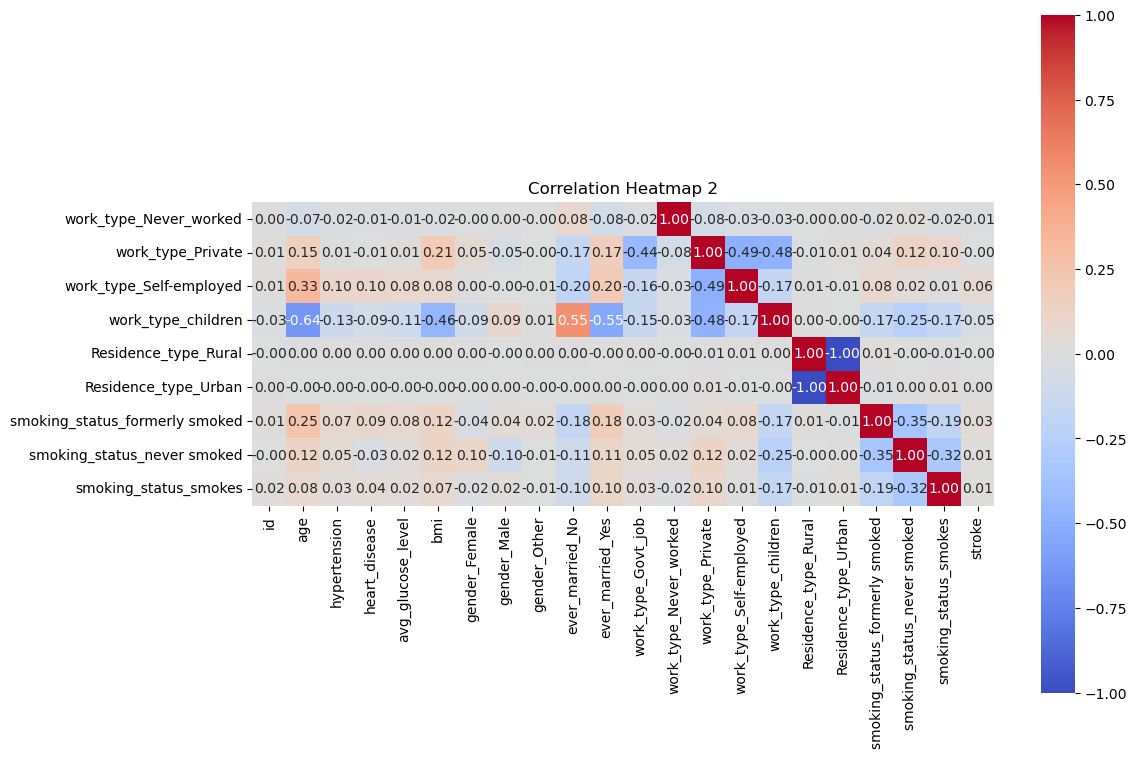

In [9]:
corr = df_train.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr[1:11],
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True
)

plt.title("Correlation Heatmap 1")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr[12:21],
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True
)

plt.title("Correlation Heatmap 2")
plt.tight_layout()
plt.show()

### Belangrijkste bevindingen

Het lijkt erop dat er geen enkele van de kolommen sterk correleerd met of iemand een beroerte heeft. Er zijn ook heel veel dummie variabelen gemaakt waardoor er veel kolommen zijn die met elkaar correleren. Dit zou opgeschoond moeten worden voordat we modellen gaan trainen

### Beschrijving van kolommen

| Kolom | Beschrijving | Datatype |
| :--- | :--- | :---: |
| id | Unieke identificatie voor de rij | int |
| age | Leeftijd van de persoon | float |
| hypertension | 0 of 1 voor of iemand een hoge bloeddruk heeft | int |
| heart_disease | 0 of 1 voor of iemand een hartziekte heeft | int |
| avg_glucose_level | De gemiddelde glucose level van de persoon | float |
| bmi | De bmi van de persoon | float |
| gender_Female | true of false voor of iemand een vrouw is | boolean |
| gender_Male | true of false voor of iemand een man is | boolean |
| gender_Other | true of false voor of iemand iets anders is dan man of vrouw | boolean |
| ever_married_No | true of false voor of iemand nog nooit getrouwd is | boolean |
| ever_married_Yes | true of false voor of iemand ooit getrouwd is | boolean |
| work_type_Never_worked | true of false voor of iemand die nog nooit gewerkt heeft | boolean |
| work_type_Private | true of false voor of iemand die zijn werk type privé wilt houden| boolean |
| work_type_Self-employed | true of false voor of iemand die zzp'er is | boolean |
| work_type_Children | true of false voor of iemand die kinderen verzorgd als werktype | boolean |
| Residence_type_Rural | true of false voor of iemand landelijk leeft | boolean |
| Residence_type_Urban | true of false voor of iemand stedelijk leeft | boolean |
| smoking_status_formerly smoked | true of false voor of iemand ooit gerookt heeft | boolean |
| smoking_status_never smoked | true of false voor of iemand nog nooit gerookt heeft | boolean |
| smoking_status_smokes | true of false voor of iemand rookt | boolean |
| stroke | 0 of 1 voor of iemand een beroerte heeft | int |


### Voldoet de dataset aan de minimale vereisten van machine learning

Nog niet. De dataset voldoet aan dat het in een pandas DataFrame zit en dat er geen missende waardes zijn, maar niet alle waardes zijn numeriek.

## 5. Evaluatie Metrics

De metrics die je gebruikt hangen af van wat voor model het is, een simpele splitsing hiervoor is classificatie en regressie.

Bij regressie kan je de MAE(Mean Absolute Error), MSE(Mean Squared Error), RMSE(Root Mean Squared Error) en R2(R-Squared) gebruiken.

Bij classificatie kan je Recall, Precision, Accuracy en de F1 Score gebruiken

Bij ons gaat het nu om classificatie dus zijn de mogelijkheden: Recall, Precision, Accuracy en F1 Score.

In de komende uitleggen zullen we wat afkortingen gebruiken:
- TP = True positives, hoeveel van de door het model voorspelde positieve gevallen ook echt positief zijn.
- FP = False positives, hoeveel van de door het model voorspelde positieve gevallen eigenlijk echt negatief zijn.
- TN = True negatives, hoeveel van de door het model voorspelde negatieve gevallen ook echt negatief zijn.
- FN = False negatives, hoeveel van de door het model voorspelde negatieve gevallen eigenlijk echt positief zijn.

Uitleg van de metrics:

- Recall: Recall geeft het percentage van de echte positieve gevallen het model correct voorspelt, de formule is TP / (TP + FN)
- Precision: Precision geeft het percentage van de door het model voorspelde positieve gevallen het als positief heeft voorspelt, de formule is TP / (TP + FP)
- Accuracy: 

## 6. Preprocessing & train-test split

### Keuzes
- Kolommen van eerdere dummy variabelen worden verwijderd. Dit is gedaan omdat we dummy trap willen voorkomen, wat inhoudt dat een feature 100 procent de andere feature kan voorspellen, waardoor je niet meer individuele correlatie met de target kan stellen.
- We hadden gekozen voor een 66/33 train, test split.
- We gaan de volgende modellen testen
  - K-Nearest Neighbors
  - Logistic Regression
  - SVM
  - Decision Tree
  - Ensembles 
    - Random Forest, 
    - Gradient Boosted Boosted Decistion Trees
    - XGboost
    - Zelf samengesteld ensemble

<br>

- De dataset is imbalanced, dit komt omdat er veel minder mensen zijn die daadwerkelijk een herseninfarct hebben (stroke = 1). hierdoor is deze groep aanzienlijk kleiner dan de mensen die geen herseninfarct hebben (stroke = 0)
  - omdat de dataset imbalanced is, zullen wij SMOTE gaan gebruiken. SMOTE vergroot de groep die in de minderheid is
- De dataset wordt later per model nog gestandaardiseerd en SMOTE wordt toegepast
  - Standaardiseren betekent hoeveel standaarddeviaties een punt van het gemiddelde van zijn kolom zit. De reden dat hiervoor gekozen is, is omdat we veel waardes hebben die 0 of 1 zijn, wat veel minder kan wegen dan bijvoorbeeld leeftijd (wat tussen de 1-99 kan zijn).


In [10]:
df_cleaned = df_train.copy()

df_cleaned = df_cleaned.drop(['id', 'gender_Male', 'ever_married_No', 'work_type_children', 'Residence_type_Urban', 'smoking_status_smokes'], axis=1)

df_cleaned = df_cleaned.astype(int)

test_cleaned = df_test.copy()

test_cleaned = test_cleaned.drop(['id', 'gender_Male', 'ever_married_No', 'work_type_children', 'Residence_type_Urban', 'smoking_status_smokes'], axis=1)

test_cleaned = test_cleaned.astype(int)


In [ ]:
from sklearn.feature_selection import f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, classification_report
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


X = df_cleaned.drop(columns=["stroke"])
y = df_cleaned["stroke"]

df_test_features = test_cleaned.copy()

scores, p_values = f_classif(X, y)

feature_scores = pd.DataFrame({
    "feature": X.columns,
    "F_score": scores,
    "p_value": p_values
}).sort_values("p_value")

print(feature_scores)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)


                           feature     F_score        p_value
0                              age  757.926360  5.204613e-165
2                    heart_disease  371.292589   2.729232e-82
1                     hypertension  238.505738   1.274364e-53
3                avg_glucose_level  198.985913   4.677923e-45
7                 ever_married_Yes  148.582019   4.179271e-34
11         work_type_Self-employed  128.966818   7.818600e-30
13  smoking_status_formerly smoked   39.037557   4.207168e-10
4                              bmi   14.140233   1.699637e-04
14     smoking_status_never smoked    3.285747   6.989276e-02
5                    gender_Female    2.555389   1.099282e-01
9           work_type_Never_worked    2.216121   1.365852e-01
10               work_type_Private    0.817603   3.658884e-01
8               work_type_Govt_job    0.661048   4.161961e-01
12            Residence_type_Rural    0.236363   6.268486e-01
6                     gender_Other    0.093918   7.592566e-01


## 7. Modelontwikkeling & evalutatie

We trainen de volgende modellen. Hierbij zullen we ook vragen beantwoorden die ons toegewezen zijn over de werking van deze modellen.
<br>
  <b> 7.1. K-Nearest Neighbors</b>
<br>
  <b> 7.2. Logistic Regression</b>
<br>
  <b> 7.3. SVM </b>
<br>
  <b> 7.4. Decision Tree </b>
<br>
  <b> 7.5. Ensembles </b>
<br>
  <b> 7.5.1. Random Forest </b>
<br>
  <b> 7.5.2. Gradient Boosted Boosted Decistion Trees </b>
<br>
  <b> 7.5.3. XGboost </b>
<br>
  <b> 7.6. Zelf samengesteld ensemble </b>


### 7.1. K-Nearest Neighbors

<b>Vragen </b>

- ***Leg uit hoe model werkt. Gebruik daarin onder andere termen “afstand”, “euclidean” en “manhattan.***
</br>
Bij K-Nearest Neighbors wordt een model getraind op basis van afstanden tussen punten. Op basis van het aantal punten dat je doorgeeft kan het model niet-lineaire lijnen trekken om zo eilandjes te maken. Bij euclidean worden de afstanden bepaald op basis van de wortel van het kwadraad van de verschil tussen 2 punten. Bij manhattan wordt de absolute waarde gebruikt om de afstand tussen 2 punten te bepalen.

- ***Leg uit waarom standaardisatie voor dit model van groot belang is.***
</br>
Standaardisatie is voor dit model belangrijk omdat de schaal van een feature ervoor kan zorgen dat een feature met een groot getal volledige invloed heeft op de target voorspellen en een feature met een klein getal vrijwel geen invloed zal hebben.

- ***Bepaal bij welke hyperparameters het model de beste resultaten geeft op de gekozen metric.***
</br>
'knn__metric': 'euclidean', 'knn__n_neighbors': 21, 'knn__weights': 'distance', 'smote__k_neighbors': 10

- ***Leg uit hoe regularisatie werkt voor dit model***
</br>
Regularisatie werkt door de K (aantal punten) aan te passen. Met een lage K overfit je vaak waardoor lijnen te strak langs punten liggen. Met een te hoge K underfit je vaak waardoor je vaak te algemeen lijnen trekt.

</br>
<b>Code</b>

In [ ]:
import numpy as np
import pandas as pd

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, classification_report


knn_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "smote__k_neighbors": [2, 3, 5, 7, 10],

    "knn__n_neighbors": [
        1, 3, 5, 7, 9, 11, 15, 21, 31
    ],

    "knn__metric": [
        "euclidean",
        "manhattan"
    ],

    "knn__weights": [
        "uniform",
        "distance"
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)


grid_search.fit(X_train, y_train)

print(
    "Best parameters:",
    grid_search.best_params_
)

print(
    "Best CV F1:",
    grid_search.best_score_
)

best_knn = grid_search.best_estimator_


submission_predictions = best_knn.predict(df_test_features)

knn_submission = pd.DataFrame({
    "id": df_test["id"],
    "stroke": submission_predictions
})

knn_submission.set_index("id", inplace=True)

print(knn_submission.head())

knn_submission.to_csv("knn_submission.csv")

print("Predictions saved to knn_submission.csv")

Fitting 5 folds for each of 180 candidates, totalling 900 fits
Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 21, 'knn__weights': 'distance', 'smote__k_neighbors': 10}
Best CV F1: 0.08356901749312445
       stroke
id           
32840       0
45158       0
56105       0
3112        0
35224       1
Predictions saved to knn_submission.csv


## 7.2. Logistic Regression

<b>Vragen </b>

- ***Leg uit hoe het model werkt.***
</br>
Logistic Regression werkt door een lineaire formule zoals b0 + b1 * x1 + bn * xn te maken en hierop een Sigmoid functie toe te passen. Hierdoor worden alleen waarden tussen 0 en 1 voorspeld. Door tijdens het model te trainen een baseline te bepalen tussen 0 en 1 (standaard 0.5) kan je waarde 0 of 1 geven op basis van of dit punt onder of boven de baseline ligt.

- ***Toon de wiskundig formule voor de loss-functie en licht deze toe.***
</br>
 1/n [y_true_i / log(y_pred_i) + (1-y_true_i) / log(1-y_pred_i)]
</br>
Deze formule heet de cross entropy loss. Het werkt door de werkelijke waardes te delen door de log voorspelde waarde. Omdat de werkelijke waarde alleen 0 of 1 kan zijn, zal het voor komen dat alleen het linkerdeel y_true_i / log(y_pred_i) toepasbaar is als y_true_i = 2 en het rechterdeel (1-y_true_i) / log(1-y_pred_i) alleen toepasbaar is als y_true_i = 0

- ***Leg uit wat gradient descent is in deze context. Leg dit uit aan de hand van een eenvoudig rekenvoorbeeld en geef hierbij de relevant wiskundige formules.***
</br>


- ***Benoem de vormen van regularisatie die van toepassing zijn op dit model.***
</br>
Bij Logistic Regression kan je Ridge of Lasso gebruiken. Deze zullen de coëfficiënten dichterbij 0 trekken. Het verschil hierbij is dat Lasso je waarde naar 0 kan brengen, terwijl Ridge alleen maar waardes dichtbij 0 kan trekken.

- ***Leg aan de hand van wiskundige formules uit hoe iedere vorm werkt en wat het effect is van iedere vorm.***
</br>
Lasso werkt met de absolute waardes van de coëfficiënten toe te voegen aan de loss-functie. Ridge werkt met de kwadraad van de coëfficiënten toe te voegen aan de loss-functie.

- ***Beschrijf hoe regularisatie zich verhoudt ten opzichte van overfitting?***
</br>


- ***Bepaal bij welke hyperparameters het model de beste resultaten geeft op de gekozen metric.***
</br>
'logreg__C': 1, 'logreg__class_weight': {0: 1, 1: 10}, 'logreg__penalty': 'l2'


</br>
<b>Code </b>

In [12]:
logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        solver="liblinear",
        random_state=42
    ))
])

param_grid = {
    "logreg__penalty": ["l1", "l2"],
    "logreg__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logreg__class_weight": [
        None,
        "balanced",
        {0: 1, 1: 2},
        {0: 1, 1: 3},
        {0: 1, 1: 5},
        {0: 1, 1: 10}
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


grid_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)


print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

best_logreg = grid_search.best_estimator_

oof_probabilities = cross_val_predict(
    best_logreg,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = np.arange(0.01, 0.51, 0.01)

threshold_results = []

for threshold in thresholds:

    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    f1 = f1_score(
        y_train,
        oof_predictions
    )

    threshold_results.append({
        "threshold": threshold,
        "f1": f1
    })


threshold_results = pd.DataFrame(
    threshold_results
)


best_threshold = threshold_results.loc[
    threshold_results["f1"].idxmax(),
    "threshold"
]

best_oof_f1 = threshold_results["f1"].max()


print("Optimal threshold:", best_threshold)
print("OOF F1:", best_oof_f1)

test_probabilities = best_logreg.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)


print(
    "Test F1:",
    f1_score(y_test, test_predictions)
)

print(
    classification_report(
        y_test,
        test_predictions
    )
)
test_probabilities_final = (
    best_logreg.predict_proba(df_test_features)[:, 1]
)

logreg_submission_predictions = (
    test_probabilities_final >= best_threshold
).astype(int)

logreg_submission = pd.DataFrame({
    "id": df_test["id"],
    "stroke": logreg_submission_predictions
})


logreg_submission.to_csv(
    "logreg_submission.csv",
    index=False
)


print("Saved predictions to logreg_submission.csv")
print(logreg_submission.head())
print("\nPrediction distribution:")
print(logreg_submission["stroke"].value_counts())

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters: {'logreg__C': 1, 'logreg__class_weight': {0: 1, 1: 10}, 'logreg__penalty': 'l2'}
Best CV F1: 0.14946705763393925
Optimal threshold: 0.47000000000000003
OOF F1: 0.16557377049180327
Test F1: 0.10877192982456141
              precision    recall  f1-score   support

           0       0.99      0.97      0.98     10901
           1       0.08      0.18      0.11       171

    accuracy                           0.95     11072
   macro avg       0.53      0.57      0.54     11072
weighted avg       0.97      0.95      0.96     11072

Saved predictions to logreg_submission.csv
      id  stroke
0  32840       0
1  45158       0
2  56105       0
3   3112       0
4  35224       0

Prediction distribution:
stroke
0    8081
1     307
Name: count, dtype: int64
